In [1]:
# 1: IMPORT LIBRARIES & LOAD DATA
# Phase 2: Preprocessing & RFM Engineering

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print(" Libraries imported successfully!")

# Load the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
df = pd.read_excel(url)

print(f" Dataset loaded! Shape: {df.shape}")
display(df.head())

 Libraries imported successfully!
 Dataset loaded! Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# 2: INITIAL DATA QUALITY CHECK

print("="*60)
print("INITIAL DATA QUALITY CHECK")
print("="*60)

# Check missing values
print("\n Missing Values:")
print(df.isnull().sum())

# Check duplicates
print(f"\n Duplicate rows: {df.duplicated().sum()}")

# Check negative quantities
negative_qty = df[df['Quantity'] < 0]
print(f"\n Rows with negative Quantity (returns): {len(negative_qty)} ({len(negative_qty)/len(df)*100:.2f}%)")

# Check invalid prices
invalid_price = df[df['UnitPrice'] <= 0]
print(f"\n Rows with invalid UnitPrice (<=0): {len(invalid_price)} ({len(invalid_price)/len(df)*100:.2f}%)")

INITIAL DATA QUALITY CHECK

 Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

 Duplicate rows: 5268

 Rows with negative Quantity (returns): 10624 (1.96%)

 Rows with invalid UnitPrice (<=0): 2517 (0.46%)


In [3]:
# 3: HANDLE MISSING VALUES

print("="*60)
print("HANDLING MISSING VALUES")
print("="*60)

# Count rows before cleaning
print(f"\n Rows before cleaning: {len(df)}")

# Remove rows without CustomerID (cannot be used for customer-level analysis)
df_clean = df.dropna(subset=['CustomerID'])

# Remove rows with missing Description (optional, but good for product analysis)
df_clean = df_clean.dropna(subset=['Description'])

print(f" Rows after removing missing CustomerID and Description: {len(df_clean)}")
print(f" Rows removed: {len(df) - len(df_clean)} ({((len(df)-len(df_clean))/len(df))*100:.2f}%)")

# Check remaining missing values
print("\n Remaining missing values:")
print(df_clean.isnull().sum())

HANDLING MISSING VALUES

 Rows before cleaning: 541909
 Rows after removing missing CustomerID and Description: 406829
 Rows removed: 135080 (24.93%)

 Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [4]:
# 4: REMOVE DUPLICATES & INVALID VALUES

print("="*60)
print("REMOVING DUPLICATES & INVALID VALUES")
print("="*60)

# Remove duplicates
df_clean = df_clean.drop_duplicates()
print(f" Rows after removing duplicates: {len(df_clean)}")

# Remove rows with negative Quantity (returns) - optional, we keep them for now
# But for revenue calculation, we need to handle them carefully
# We'll keep them and handle revenue calculation with Quantity * UnitPrice

# Remove rows with invalid UnitPrice (<= 0)
df_clean = df_clean[df_clean['UnitPrice'] > 0]
print(f" Rows after removing invalid UnitPrice: {len(df_clean)}")

# Remove rows where Quantity is 0
df_clean = df_clean[df_clean['Quantity'] != 0]
print(f" Rows after removing zero Quantity: {len(df_clean)}")

print("\n Data Cleaning Complete!")
print(f" Final shape: {df_clean.shape}")

REMOVING DUPLICATES & INVALID VALUES
 Rows after removing duplicates: 401604
 Rows after removing invalid UnitPrice: 401564
 Rows after removing zero Quantity: 401564

 Data Cleaning Complete!
 Final shape: (401564, 8)


CONVERT DATES & CREATE REVENUE
 InvoiceDate converted to datetime
 Revenue column created

 Revenue Statistics:
count    401564.000000
mean         20.615691
std         430.373603
min     -168469.600000
25%           4.250000
50%          11.700000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64


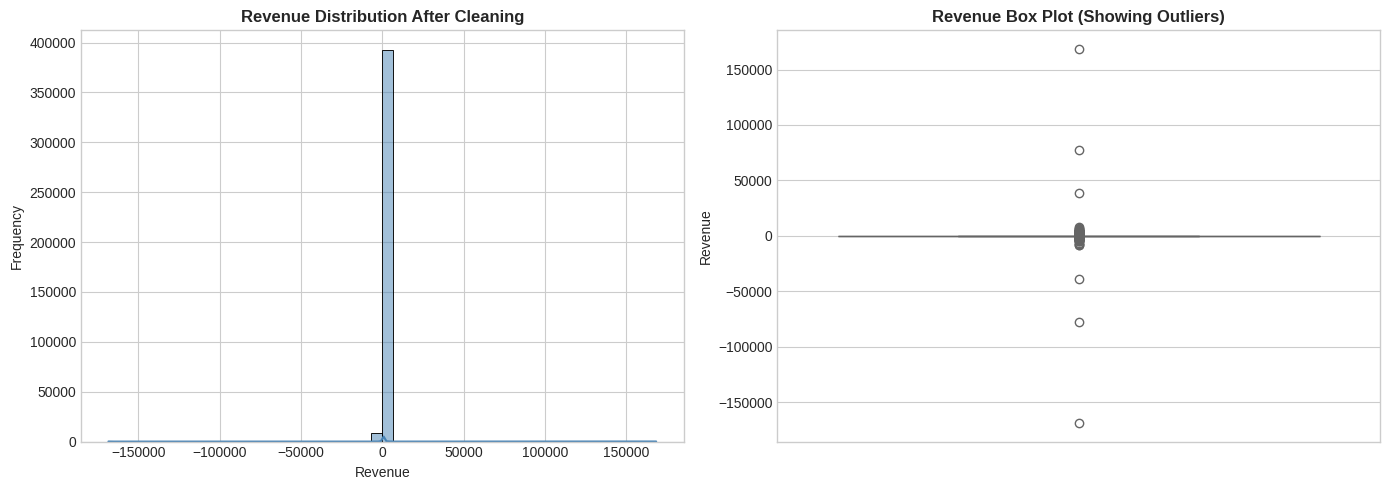

In [5]:
# 5: CONVERT DATES & CREATE REVENUE

print("="*60)
print("CONVERT DATES & CREATE REVENUE")
print("="*60)

# Convert InvoiceDate to datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
print(f" InvoiceDate converted to datetime")

# Create Revenue column (Quantity * UnitPrice)
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']
print(f" Revenue column created")

# Display summary
print(f"\n Revenue Statistics:")
print(df_clean['Revenue'].describe())

# Visualize revenue distribution after cleaning
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(df_clean['Revenue'], kde=True, bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Revenue Distribution After Cleaning', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue')
axes[0].set_ylabel('Frequency')

# Box plot
sns.boxplot(y=df_clean['Revenue'], ax=axes[1], color='coral')
axes[1].set_title('Revenue Box Plot (Showing Outliers)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Revenue')

plt.tight_layout()
plt.savefig('revenue_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

HANDLING OUTLIERS USING IQR METHOD

 Quantity outliers: 26637 (6.63%)
   IQR bounds: Lower=-13.00, Upper=27.00

 UnitPrice outliers: 35802 (8.92%)
   IQR bounds: Lower=-2.50, Upper=7.50

 Rows after removing Quantity outliers: 374927
 Rows after removing UnitPrice outliers: 339422
 Total rows removed: 62142 (15.47%)


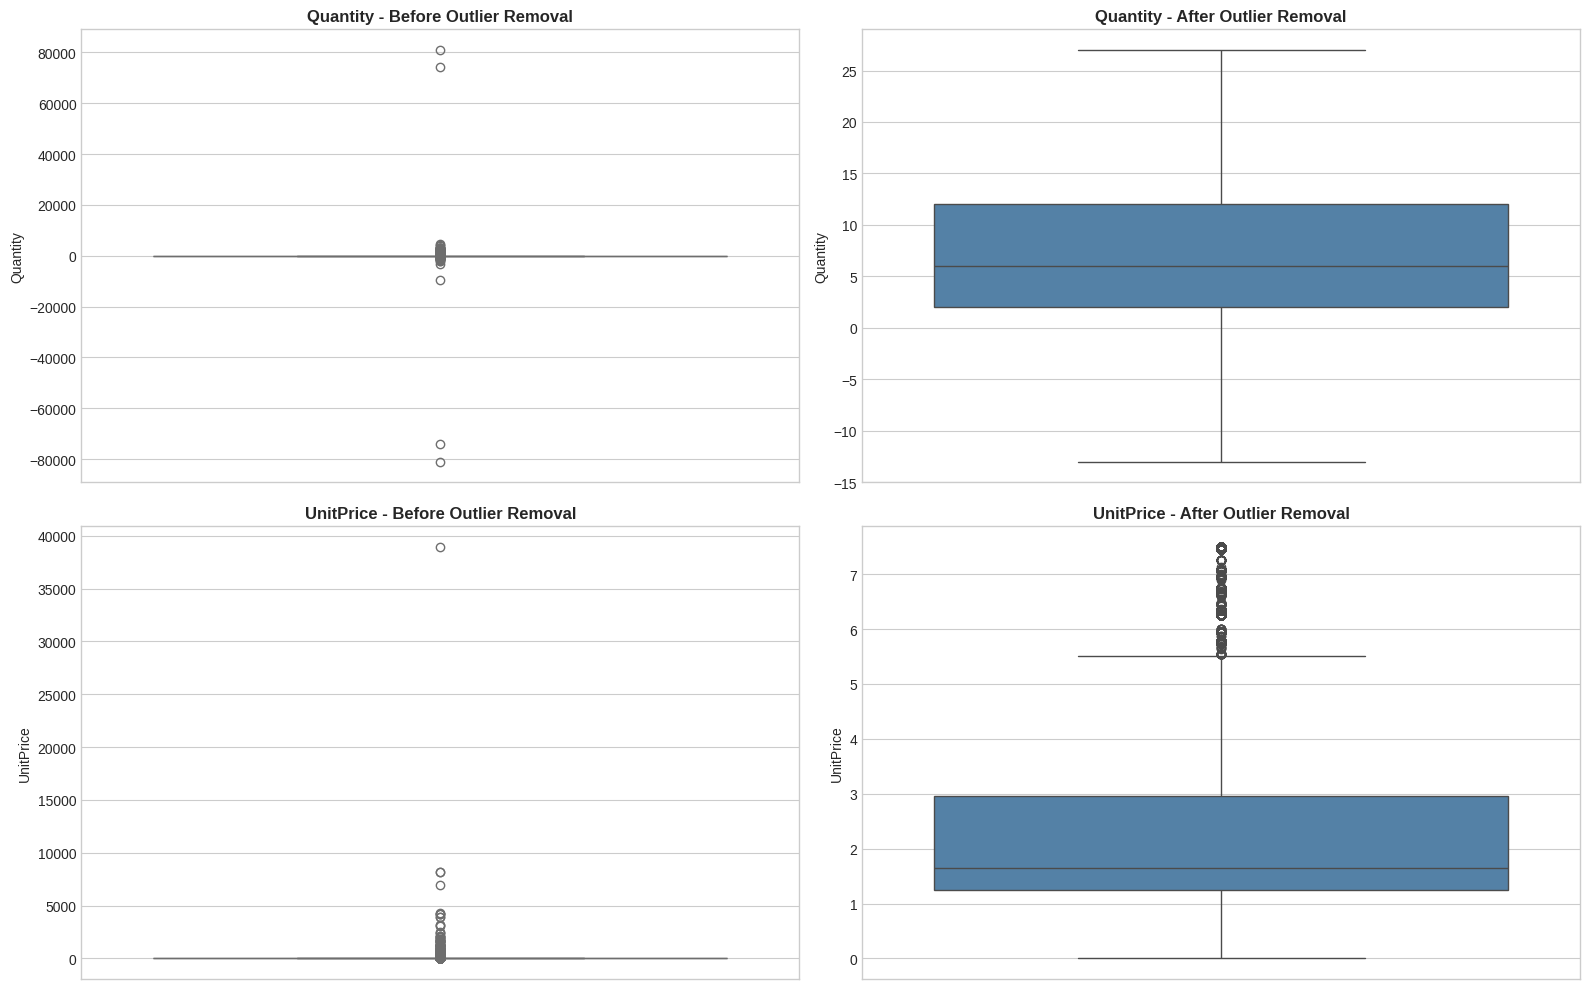


 Outlier handling complete!
 Final shape: (339422, 9)


In [6]:
# 6: HANDLE OUTLIERS USING IQR METHOD

print("="*60)
print("HANDLING OUTLIERS USING IQR METHOD")
print("="*60)

# Function to detect outliers using IQR
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Check outliers in Quantity
qty_outliers, qty_lower, qty_upper = detect_outliers_iqr(df_clean, 'Quantity')
print(f"\n Quantity outliers: {len(qty_outliers)} ({len(qty_outliers)/len(df_clean)*100:.2f}%)")
print(f"   IQR bounds: Lower={qty_lower:.2f}, Upper={qty_upper:.2f}")

# Check outliers in UnitPrice
price_outliers, price_lower, price_upper = detect_outliers_iqr(df_clean, 'UnitPrice')
print(f"\n UnitPrice outliers: {len(price_outliers)} ({len(price_outliers)/len(df_clean)*100:.2f}%)")
print(f"   IQR bounds: Lower={price_lower:.2f}, Upper={price_upper:.2f}")

# Remove outliers from Quantity
df_no_outliers = df_clean[(df_clean['Quantity'] >= qty_lower) & (df_clean['Quantity'] <= qty_upper)]
print(f"\n Rows after removing Quantity outliers: {len(df_no_outliers)}")

# Remove outliers from UnitPrice
df_no_outliers = df_no_outliers[(df_no_outliers['UnitPrice'] >= price_lower) & (df_no_outliers['UnitPrice'] <= price_upper)]
print(f" Rows after removing UnitPrice outliers: {len(df_no_outliers)}")

print(f" Total rows removed: {len(df_clean) - len(df_no_outliers)} ({((len(df_clean)-len(df_no_outliers))/len(df_clean))*100:.2f}%)")

# Visualize before/after comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Quantity before
sns.boxplot(y=df_clean['Quantity'], ax=axes[0,0], color='lightcoral')
axes[0,0].set_title('Quantity - Before Outlier Removal', fontsize=12, fontweight='bold')
axes[0,0].set_ylabel('Quantity')

# Quantity after
sns.boxplot(y=df_no_outliers['Quantity'], ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Quantity - After Outlier Removal', fontsize=12, fontweight='bold')
axes[0,1].set_ylabel('Quantity')

# UnitPrice before
sns.boxplot(y=df_clean['UnitPrice'], ax=axes[1,0], color='lightcoral')
axes[1,0].set_title('UnitPrice - Before Outlier Removal', fontsize=12, fontweight='bold')
axes[1,0].set_ylabel('UnitPrice')

# UnitPrice after
sns.boxplot(y=df_no_outliers['UnitPrice'], ax=axes[1,1], color='steelblue')
axes[1,1].set_title('UnitPrice - After Outlier Removal', fontsize=12, fontweight='bold')
axes[1,1].set_ylabel('UnitPrice')

plt.tight_layout()
plt.savefig('outlier_removal_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Update dataframe
df_clean = df_no_outliers.copy()
print("\n Outlier handling complete!")
print(f" Final shape: {df_clean.shape}")

CREATING RFM FEATURES
 Reference date: 2011-12-09 12:50:00

 RFM Metrics Summary:
         CustomerID      Recency    Frequency      Monetary
count   4221.000000  4221.000000  4221.000000   4221.000000
mean   15293.559583    91.165364     4.612888   1007.026597
std     1720.482973   100.733227     8.254102   2166.801829
min    12347.000000     0.000000     1.000000   -240.640000
25%    13810.000000    16.000000     1.000000    200.310000
50%    15289.000000    49.000000     2.000000    458.100000
75%    16773.000000   144.000000     5.000000   1108.020000
max    18287.000000   373.000000   232.000000  83220.230000

 RFM Dataframe shape: (4221, 6)


,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity
0,12347.0,1,7,3314.73,19.968253,1893
1,12348.0,248,3,90.20,15.033333,140
2,12349.0,18,1,999.15,17.226724,523
3,12350.0,309,1,294.40,18.400000,196
4,12352.0,35,8,1010.61,13.843973,437


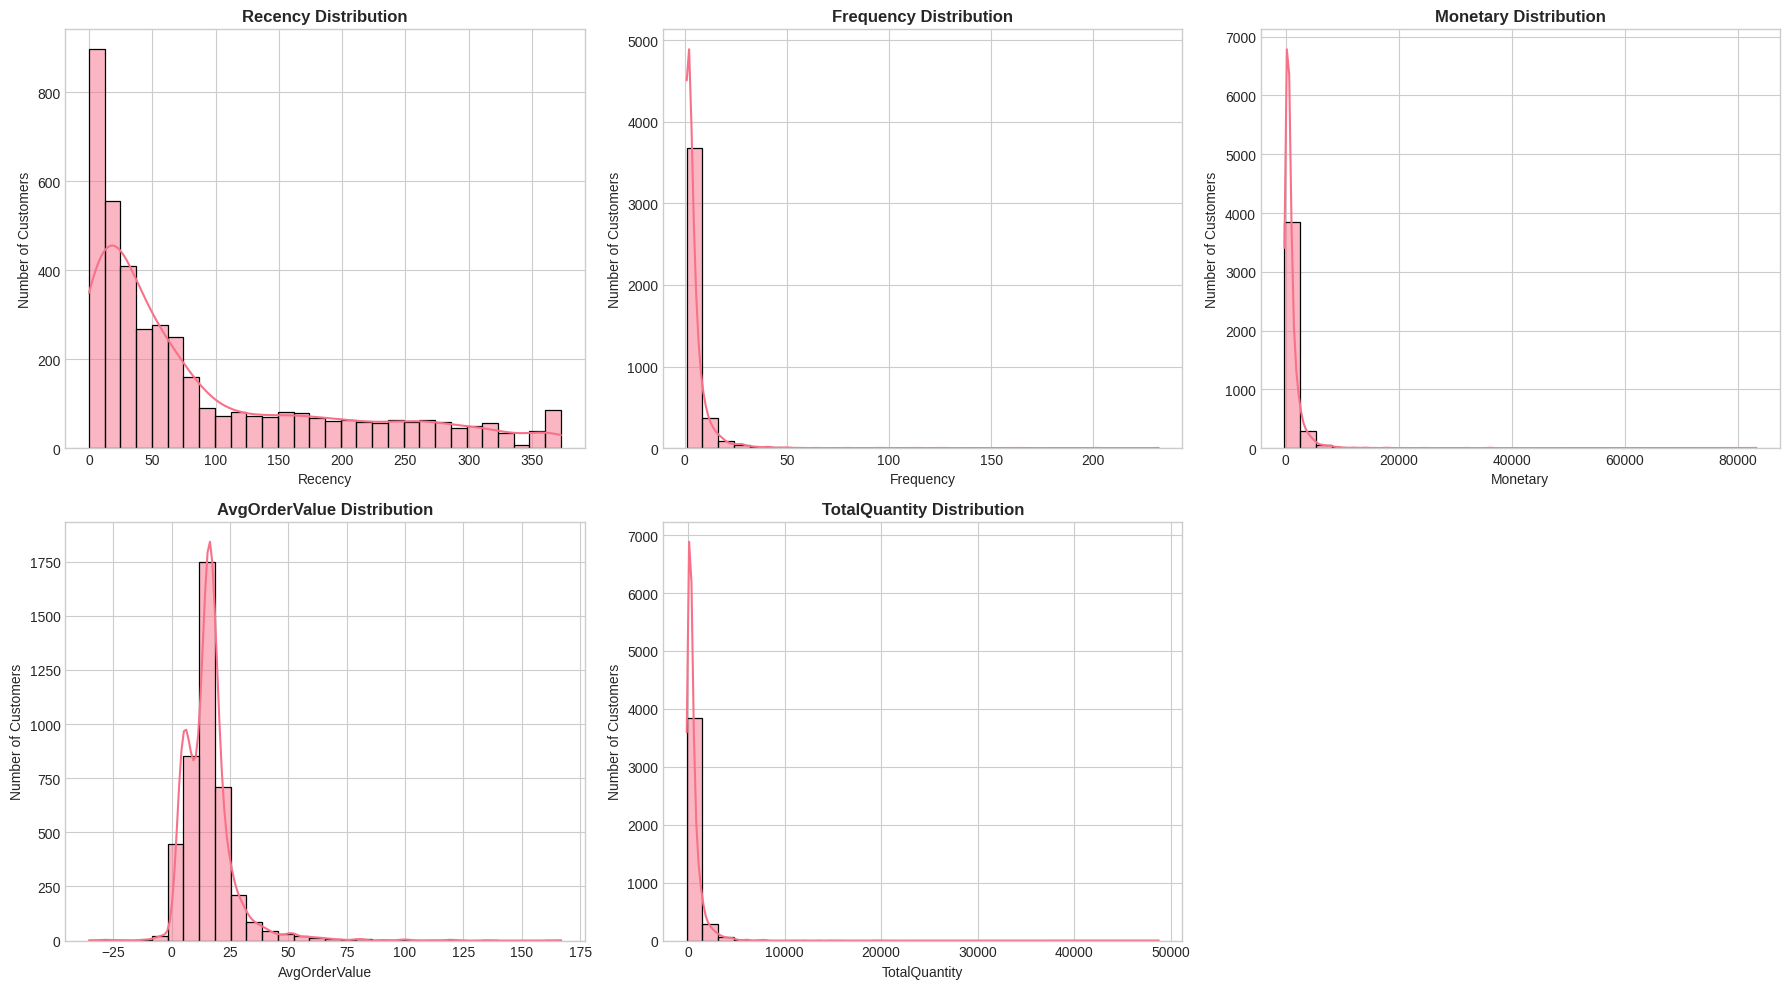

In [7]:
# 7: CREATE RFM FEATURES

print("="*60)
print("CREATING RFM FEATURES")
print("="*60)

# Set reference date (last purchase date in dataset)
reference_date = df_clean['InvoiceDate'].max()
print(f" Reference date: {reference_date}")

# Calculate RFM metrics per customer
rfm_df = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',                                     # Frequency
    'Revenue': 'sum'                                            # Monetary
}).reset_index()

# Rename columns
rfm_df.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print(f"\n RFM Metrics Summary:")
print(rfm_df.describe())

# Add additional features
# Add Average Order Value
avg_order = df_clean.groupby('CustomerID')['Revenue'].mean().reset_index()
avg_order.columns = ['CustomerID', 'AvgOrderValue']
rfm_df = rfm_df.merge(avg_order, on='CustomerID')

# Add Total Quantity
total_qty = df_clean.groupby('CustomerID')['Quantity'].sum().reset_index()
total_qty.columns = ['CustomerID', 'TotalQuantity']
rfm_df = rfm_df.merge(total_qty, on='CustomerID')

print(f"\n RFM Dataframe shape: {rfm_df.shape}")
display(rfm_df.head())

# Visualize RFM distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

rfm_features = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'TotalQuantity']

for idx, feature in enumerate(rfm_features):
    row = idx // 3
    col = idx % 3
    if idx < 5:
        sns.histplot(rfm_df[feature], kde=True, bins=30, ax=axes[row, col])
        axes[row, col].set_title(f'{feature} Distribution', fontsize=12, fontweight='bold')
        axes[row, col].set_xlabel(feature)
        axes[row, col].set_ylabel('Number of Customers')

# Remove empty subplot
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.savefig('rfm_features_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# 8: HANDLE OUTLIERS IN RFM FEATURES

print("="*60)
print("HANDLING OUTLIERS IN RFM FEATURES")
print("="*60)

# Check outliers in RFM features
rfm_features = ['Recency', 'Frequency', 'Monetary']

for feature in rfm_features:
    outliers, lower, upper = detect_outliers_iqr(rfm_df, feature)
    print(f"\n {feature} outliers: {len(outliers)} ({len(outliers)/len(rfm_df)*100:.2f}%)")
    print(f"   IQR bounds: Lower={lower:.2f}, Upper={upper:.2f}")

# Remove outliers using IQR method (for all RFM features combined)
# We'll use a more lenient approach: remove rows where ANY feature is an outlier

# Create mask for outliers
outlier_mask = pd.Series(False, index=rfm_df.index)

for feature in rfm_features:
    Q1 = rfm_df[feature].quantile(0.25)
    Q3 = rfm_df[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    feature_outliers = (rfm_df[feature] < lower_bound) | (rfm_df[feature] > upper_bound)
    outlier_mask = outlier_mask | feature_outliers

print(f"\n Total customers with outliers in any RFM feature: {outlier_mask.sum()}")
print(f"   Percentage: {outlier_mask.sum()/len(rfm_df)*100:.2f}%")

# Remove outliers
rfm_clean = rfm_df[~outlier_mask].copy()
print(f"\n RFM data after outlier removal: {len(rfm_clean)} customers")

# Verify outliers removed
print(f"\n RFM Metrics Summary After Outlier Removal:")
print(rfm_clean[rfm_features].describe())

HANDLING OUTLIERS IN RFM FEATURES

 Recency outliers: 126 (2.99%)
   IQR bounds: Lower=-176.00, Upper=336.00

 Frequency outliers: 327 (7.75%)
   IQR bounds: Lower=-5.00, Upper=11.00

 Monetary outliers: 386 (9.14%)
   IQR bounds: Lower=-1161.26, Upper=2469.59

 Total customers with outliers in any RFM feature: 607
   Percentage: 14.38%

 RFM data after outlier removal: 3614 customers

 RFM Metrics Summary After Outlier Removal:
           Recency    Frequency     Monetary
count  3614.000000  3614.000000  3614.000000
mean     91.231046     2.995573   588.195408
std      91.768295     2.322344   546.432296
min       0.000000     1.000000  -222.600000
25%      20.250000     1.000000   187.632500
50%      55.000000     2.000000   394.380000
75%     148.000000     4.000000   817.325000
max     336.000000    11.000000  2469.580000


FEATURE SCALING - StandardScaler
 Features to scale: ['Recency', 'Frequency', 'Monetary']
 Shape: (3614, 3)

 Scaled Features Summary:
       Recency_Scaled  Frequency_Scaled  Monetary_Scaled
count    3.614000e+03      3.614000e+03     3.614000e+03
mean     4.521993e-17     -1.966084e-17    -1.572867e-17
std      1.000138e+00      1.000138e+00     1.000138e+00
min     -9.942832e-01     -8.594113e-01    -1.484004e+00
25%     -7.735882e-01     -8.594113e-01    -7.331527e-01
50%     -3.948647e-01     -4.287524e-01    -3.547415e-01
75%      6.186974e-01      4.325656e-01     4.193773e-01
max      2.667619e+00      3.447179e+00     3.443510e+00


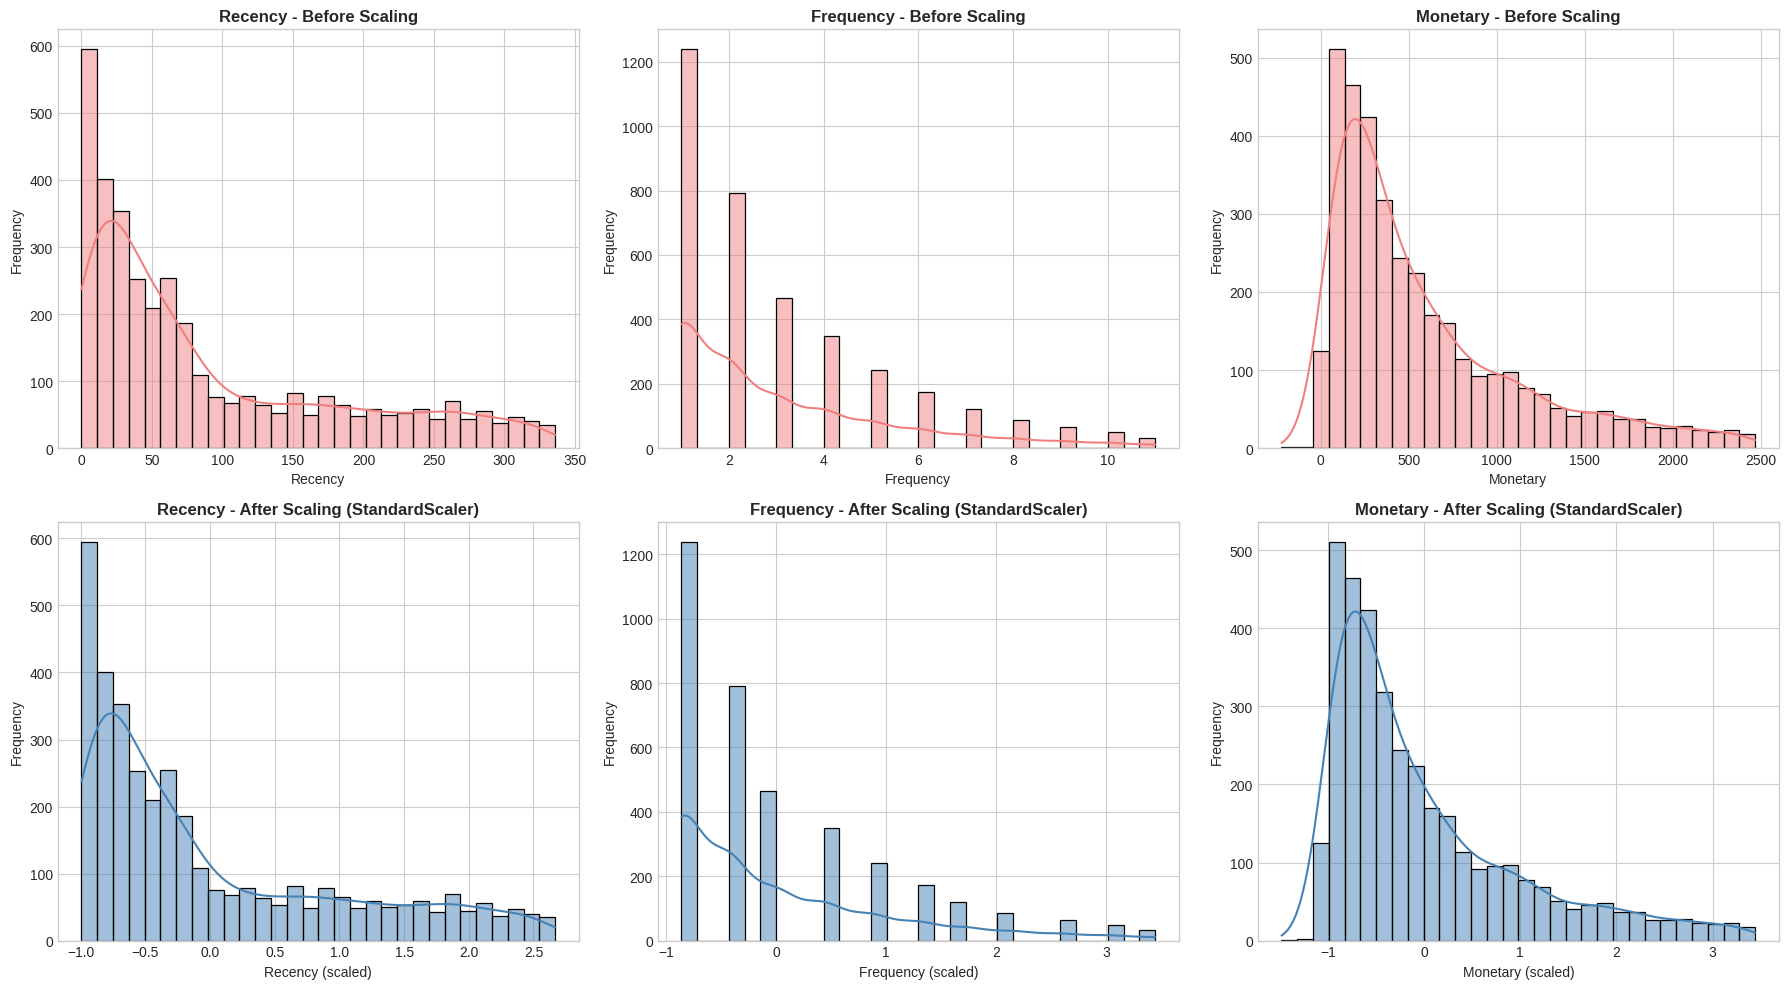


 Feature Scaling Complete!
   • Features now have mean = 0, standard deviation = 1
   • Ready for clustering algorithms (K-Means, DBSCAN, Hierarchical)


In [9]:
# 9: FEATURE SCALING - StandardScaler

print("="*60)
print("FEATURE SCALING - StandardScaler")
print("="*60)

from sklearn.preprocessing import StandardScaler

# Select features for scaling (RFM features)
features_to_scale = ['Recency', 'Frequency', 'Monetary']
X = rfm_clean[features_to_scale]

print(f" Features to scale: {features_to_scale}")
print(f" Shape: {X.shape}")

# Initialize and fit scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create dataframe with scaled features
rfm_scaled_df = rfm_clean.copy()
for idx, feature in enumerate(features_to_scale):
    rfm_scaled_df[f'{feature}_Scaled'] = X_scaled[:, idx]

print(f"\n Scaled Features Summary:")
print(rfm_scaled_df[['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled']].describe())

# Visualize before vs after scaling
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for idx, feature in enumerate(features_to_scale):
    # Before scaling
    sns.histplot(rfm_clean[feature], kde=True, bins=30, ax=axes[0, idx], color='lightcoral')
    axes[0, idx].set_title(f'{feature} - Before Scaling', fontsize=12, fontweight='bold')
    axes[0, idx].set_xlabel(feature)
    axes[0, idx].set_ylabel('Frequency')

    # After scaling
    sns.histplot(rfm_scaled_df[f'{feature}_Scaled'], kde=True, bins=30, ax=axes[1, idx], color='steelblue')
    axes[1, idx].set_title(f'{feature} - After Scaling (StandardScaler)', fontsize=12, fontweight='bold')
    axes[1, idx].set_xlabel(f'{feature} (scaled)')
    axes[1, idx].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('feature_scaling_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n Feature Scaling Complete!")
print("   • Features now have mean = 0, standard deviation = 1")
print("   • Ready for clustering algorithms (K-Means, DBSCAN, Hierarchical)")

PREPARING TRANSACTION FORMAT
 Total unique invoices: 19471

 Sample transactions:


,InvoiceNo,Products
0,536365,"[WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET..."
1,536366,"[HAND WARMER UNION JACK, HAND WARMER RED POLKA..."
2,536367,"[POPPY'S PLAYHOUSE BEDROOM , POPPY'S PLAYHOUSE..."
3,536368,"[JAM MAKING SET WITH JARS, RED COAT RACK PARIS..."
4,536369,[BATH BUILDING BLOCK WORD]



 Products per transaction statistics:
count    19471.000000
mean        17.432181
std         21.995692
min          1.000000
25%          4.000000
50%         11.000000
75%         23.000000
max        460.000000
Name: ProductCount, dtype: float64


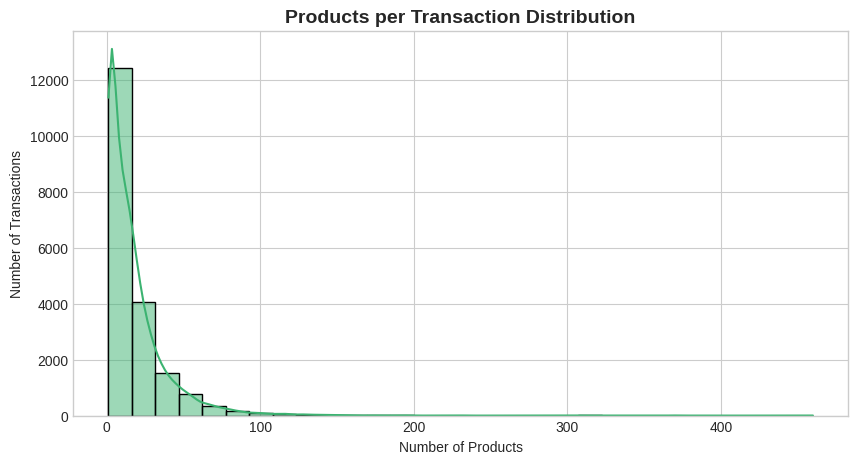


 Transaction format prepared for Association Rule Mining!
   • 19471 transactions ready
   • Will be used in Phase 4 for Product Association/Bundling


In [10]:
# 10: PREPARE TRANSACTION FORMAT
# For Association Rule Mining (Secondary Lens)

print("="*60)
print("PREPARING TRANSACTION FORMAT")
print("="*60)

# Create basket data for each Invoice
# Group by InvoiceNo and create list of products
basket_df = df_clean.groupby('InvoiceNo')['Description'].apply(list).reset_index()
basket_df.columns = ['InvoiceNo', 'Products']

print(f" Total unique invoices: {len(basket_df)}")
print(f"\n Sample transactions:")
display(basket_df.head())

# Count products per transaction
basket_df['ProductCount'] = basket_df['Products'].apply(len)
print(f"\n Products per transaction statistics:")
print(basket_df['ProductCount'].describe())

# Visualize transaction size distribution
plt.figure(figsize=(10, 5))
sns.histplot(basket_df['ProductCount'], bins=30, kde=True, color='mediumseagreen')
plt.title('Products per Transaction Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Number of Products')
plt.ylabel('Number of Transactions')
plt.savefig('transaction_size_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Prepare for Apriori: Convert to one-hot encoded format (optional, we'll do this in Phase 4)
print("\n Transaction format prepared for Association Rule Mining!")
print(f"   • {len(basket_df)} transactions ready")
print(f"   • Will be used in Phase 4 for Product Association/Bundling")

In [11]:
# 11: SAVE PREPROCESSED DATA

print("="*60)
print("SAVING PREPROCESSED DATA")
print("="*60)

# Save cleaned transaction data
cleaned_data_path = 'online_retail_cleaned.csv'
df_clean.to_csv(cleaned_data_path, index=False)
print(f" Cleaned transaction data saved: {cleaned_data_path}")

# Save RFM data (scaled and unscaled)
rfm_clean.to_csv('rfm_data.csv', index=False)
rfm_scaled_df.to_csv('rfm_data_scaled.csv', index=False)
print(f" RFM data saved: rfm_data.csv")
print(f" RFM scaled data saved: rfm_data_scaled.csv")

# Save basket data for association rules
basket_df.to_csv('basket_data.csv', index=False)
print(f" Basket data saved: basket_data.csv")

# Save scaler for later use
import pickle
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print(f" Scaler saved: scaler.pkl")

SAVING PREPROCESSED DATA
 Cleaned transaction data saved: online_retail_cleaned.csv
 RFM data saved: rfm_data.csv
 RFM scaled data saved: rfm_data_scaled.csv
 Basket data saved: basket_data.csv
 Scaler saved: scaler.pkl


In [12]:
# 12: PREPROCESSING SUMMARY REPORT

print("="*60)
print("PREPROCESSING SUMMARY REPORT")
print("="*60)

print("""
 PHASE 2: PREPROCESSING & RFM ENGINEERING COMPLETE!

 SUMMARY:
-----------
1. DATA CLEANING:
   ✓ Removed rows without CustomerID
   ✓ Removed duplicates
   ✓ Removed invalid UnitPrice (<= 0)
   ✓ Removed zero Quantity rows
   ✓ Removed outliers using IQR method

2. RFM FEATURE ENGINEERING:
   ✓ Recency: Days since last purchase
   ✓ Frequency: Number of unique invoices
   ✓ Monetary: Total revenue
   ✓ Additional features: AvgOrderValue, TotalQuantity

3. FEATURE SCALING:
   ✓ Applied StandardScaler to RFM features
   ✓ Features now have mean=0, std=1

4. DATA PREPARED:
   ✓ Transaction data (cleaned)
   ✓ RFM data (scaled and unscaled)
   ✓ Basket data (for association rules)
   ✓ Scaler saved for future use

 FINAL SHAPES:
---------------
   • Cleaned transactions: {df_clean.shape}
   • RFM data: {rfm_clean.shape}
   • Basket data: {basket_df.shape}

 FILES GENERATED:
-----------------
   • online_retail_cleaned.csv
   • rfm_data.csv
   • rfm_data_scaled.csv
   • basket_data.csv
   • scaler.pkl
   • revenue_distribution.png
   • outlier_removal_comparison.png
   • rfm_features_distributions.png
   • feature_scaling_comparison.png
   • transaction_size_distribution.png

 NEXT STEPS (Phase 3):
-----------------------
  1. Customer Segmentation using clustering algorithms
  2. K-Means, DBSCAN, Hierarchical Clustering
  3. Find optimal number of clusters (Elbow, Silhouette)
  4. Compare models and select best
  5. Create segment profiles

 RESPONSIBILITIES:
-------------------
   • Member 2: Lead this Phase
   • All members: Review and understand the processed data
   • Member 3: Prepare for Phase 3 (Segmentation)

========================================
""")

print(f"\n Final transaction count: {len(df_clean):,}")
print(f" Final customer count: {len(rfm_clean):,}")
print("\n Phase 2 Complete! Move to Phase 3: Customer Segmentation")

PREPROCESSING SUMMARY REPORT

 PHASE 2: PREPROCESSING & RFM ENGINEERING COMPLETE!

 SUMMARY:
-----------
1. DATA CLEANING:
   ✓ Removed rows without CustomerID
   ✓ Removed duplicates
   ✓ Removed invalid UnitPrice (<= 0)
   ✓ Removed zero Quantity rows
   ✓ Removed outliers using IQR method

2. RFM FEATURE ENGINEERING:
   ✓ Recency: Days since last purchase
   ✓ Frequency: Number of unique invoices
   ✓ Monetary: Total revenue
   ✓ Additional features: AvgOrderValue, TotalQuantity

3. FEATURE SCALING:
   ✓ Applied StandardScaler to RFM features
   ✓ Features now have mean=0, std=1

4. DATA PREPARED:
   ✓ Transaction data (cleaned)
   ✓ RFM data (scaled and unscaled)
   ✓ Basket data (for association rules)
   ✓ Scaler saved for future use

 FINAL SHAPES:
---------------
   • Cleaned transactions: {df_clean.shape}
   • RFM data: {rfm_clean.shape}
   • Basket data: {basket_df.shape}

 FILES GENERATED:
-----------------
   • online_retail_cleaned.csv
   • rfm_data.csv
   • rfm_data_scale